In [14]:
# Cell 1: imports and load data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the two files
features = pd.read_csv("../data/features.csv")   # what the system sees
labels = pd.read_csv("../data/labels.csv")       # hidden answers, used ONLY to color charts

# Join them on account_id so each row has features + label
df = features.merge(labels, on="account_id")

print(features.shape, labels.shape, df.shape)
df.head()

(3099, 6) (3099, 4) (3099, 9)


,account_id,account_age_days,trades_per_day,baseline_trades_per_day,linked_account_count,timing_regularity,is_anomaly,anomaly_type,difficulty
0,ACC00000,213,9.15,12.96,0,0.874,0,normal,none
1,ACC00001,394,5.27,4.38,1,0.571,0,normal,none
2,ACC00002,41,8.72,10.97,0,1.322,0,normal,none
3,ACC00003,604,2.67,2.28,0,0.947,0,normal,none
4,ACC00004,374,3.71,3.43,0,1.299,0,normal,none


In [15]:
# Cell 2: health check

# 1. Data types and non-null counts for each column
print("--- Info ---")
df.info()

# 2. Missing values per column
print("\n--- Missing values ---")
print(df.isnull().sum())

# 3. Duplicate account IDs (should be 0)
print("\n--- Duplicate account_ids ---")
print(df["account_id"].duplicated().sum())

# 4. Summary statistics for the feature columns only
print("\n--- Summary statistics ---")
feature_cols = ["account_age_days", "trades_per_day", "baseline_trades_per_day",
                "linked_account_count", "timing_regularity"]
df[feature_cols].describe().round(2)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 3099 entries, 0 to 3098
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   account_id               3099 non-null   str    
 1   account_age_days         3099 non-null   int64  
 2   trades_per_day           3099 non-null   float64
 3   baseline_trades_per_day  3099 non-null   float64
 4   linked_account_count     3099 non-null   int64  
 5   timing_regularity        3099 non-null   float64
 6   is_anomaly               3099 non-null   int64  
 7   anomaly_type             3099 non-null   str    
 8   difficulty               3099 non-null   str    
dtypes: float64(3), int64(3), str(3)
memory usage: 218.0 KB

--- Missing values ---
account_id                 0
account_age_days           0
trades_per_day             0
baseline_trades_per_day    0
linked_account_count       0
timing_regularity          0
is_anomaly                 0
anomaly_typ

,account_age_days,trades_per_day,baseline_trades_per_day,linked_account_count,timing_regularity
count,3099.00,3099.00,3099.00,3099.00,3099.00
mean,447.64,12.87,10.98,0.34,0.99
std,263.05,29.35,10.73,0.86,0.26
min,0.00,0.48,0.69,0.00,0.01
25%,220.00,4.56,4.59,0.00,0.82
50%,445.00,8.03,7.99,0.00,0.99
75%,677.50,13.91,13.36,1.00,1.16
max,900.00,879.69,126.81,12.00,2.00


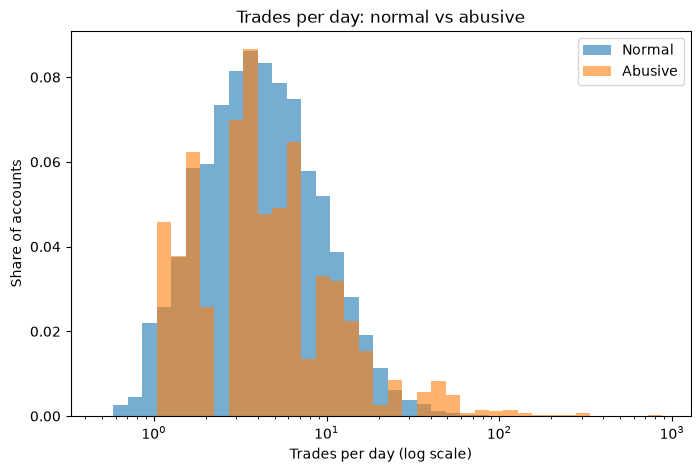

Median trades/day - normal: 7.94
Median trades/day - abusive: 14.2


In [16]:
# Cell 3: trades per day, normal vs abusive (log scale)

# Split into two groups (labels used ONLY to color the chart)
normal = df[df["is_anomaly"] == 0]
abusive = df[df["is_anomaly"] == 1]

# Bins that are evenly spaced on a log scale
bins = np.logspace(np.log10(df["trades_per_day"].min()),
                   np.log10(df["trades_per_day"].max()), 40)

plt.figure(figsize=(8, 5))
plt.hist(normal["trades_per_day"], bins=bins, alpha=0.6, density=True, label="Normal")
plt.hist(abusive["trades_per_day"], bins=bins, alpha=0.6, density=True, label="Abusive")
plt.xscale("log")
plt.xlabel("Trades per day (log scale)")
plt.ylabel("Share of accounts")
plt.title("Trades per day: normal vs abusive")
plt.legend()

# Save for the README
plt.savefig("../docs/figures/trades_per_day.png", dpi=150, bbox_inches="tight")
plt.show()

# Median for each group
print("Median trades/day - normal:", normal["trades_per_day"].median().round(2))
print("Median trades/day - abusive:", abusive["trades_per_day"].median().round(2))

group
normal           3000
bot                33
multi_account      33
trial_abuse        33
Name: count, dtype: int64

Percent of accounts by linked_account_count:
linked_account_count    0     1    2     3     4    6    7     8     9    10  \
group                                                                          
bot                   63.6  36.4  0.0   0.0   0.0  0.0  0.0   0.0   0.0  0.0   
multi_account          0.0   0.0  0.0  33.3  15.2  6.1  3.0  12.1  12.1  9.1   
normal                75.5  21.3  3.2   0.0   0.0  0.0  0.0   0.0   0.0  0.0   
trial_abuse           69.7  27.3  3.0   0.0   0.0  0.0  0.0   0.0   0.0  0.0   

linked_account_count   11   12  
group                           
bot                   0.0  0.0  
multi_account         3.0  6.1  
normal                0.0  0.0  
trial_abuse           0.0  0.0  


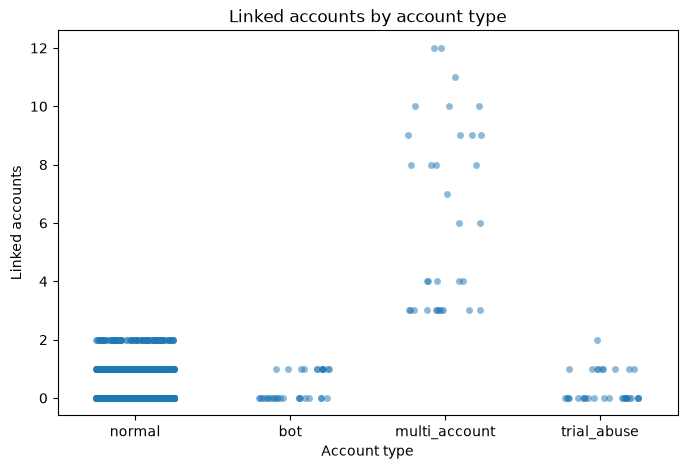

In [17]:
# Cell 4: linked account count by account type

# Normal accounts may have an empty anomaly_type, so give them a name
df["group"] = df["anomaly_type"].fillna("normal")

# Check what the group names are
print(df["group"].value_counts())

# Share of accounts at each linked-account count, per group (in %)
table = pd.crosstab(df["group"], df["linked_account_count"], normalize="index") * 100
print("\nPercent of accounts by linked_account_count:")
print(table.round(1))

# Chart: every account as a dot, spread out sideways so dots don't overlap
plt.figure(figsize=(8, 5))
sns.stripplot(data=df, x="group", y="linked_account_count", jitter=0.25, alpha=0.5)
plt.xlabel("Account type")
plt.ylabel("Linked accounts")
plt.title("Linked accounts by account type")

plt.savefig("../docs/figures/linked_accounts.png", dpi=150, bbox_inches="tight")
plt.show()

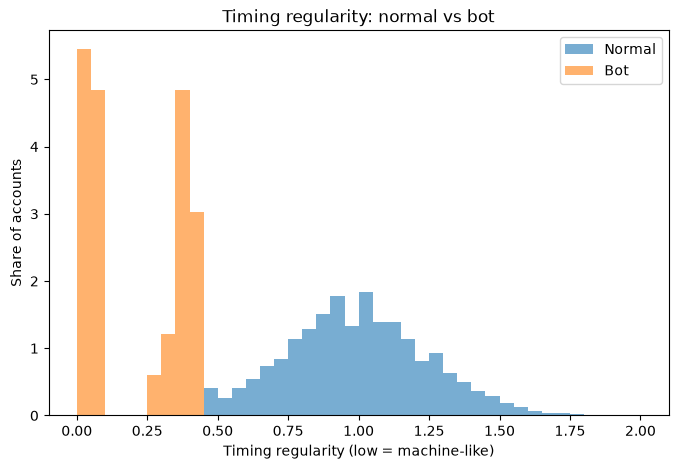

Normal - min: 0.45 | 5th percentile: 0.59
Bots   - min: 0.01 | max: 0.43
Bots above the normal 5th percentile: 0 of 33


In [18]:
# Cell 5: timing regularity, normal vs bot

# Pick out the two groups (uses the "group" column from Cell 4)
normal = df[df["group"] == "normal"]
bots = df[df["group"] == "bot"]

# Same bins for both groups so the bars line up
bins = np.linspace(0, 2, 41)

plt.figure(figsize=(8, 5))
plt.hist(normal["timing_regularity"], bins=bins, alpha=0.6, density=True, label="Normal")
plt.hist(bots["timing_regularity"], bins=bins, alpha=0.6, density=True, label="Bot")
plt.xlabel("Timing regularity (low = machine-like)")
plt.ylabel("Share of accounts")
plt.title("Timing regularity: normal vs bot")
plt.legend()

plt.savefig("../docs/figures/timing_regularity.png", dpi=150, bbox_inches="tight")
plt.show()

# Compare the numbers
print("Normal - min:", normal["timing_regularity"].min().round(2),
      "| 5th percentile:", normal["timing_regularity"].quantile(0.05).round(2))
print("Bots   - min:", bots["timing_regularity"].min().round(2),
      "| max:", bots["timing_regularity"].max().round(2))

# How many bots sit inside the normal range?
normal_low = normal["timing_regularity"].quantile(0.05)
print("Bots above the normal 5th percentile:", (bots["timing_regularity"] > normal_low).sum(), "of", len(bots))

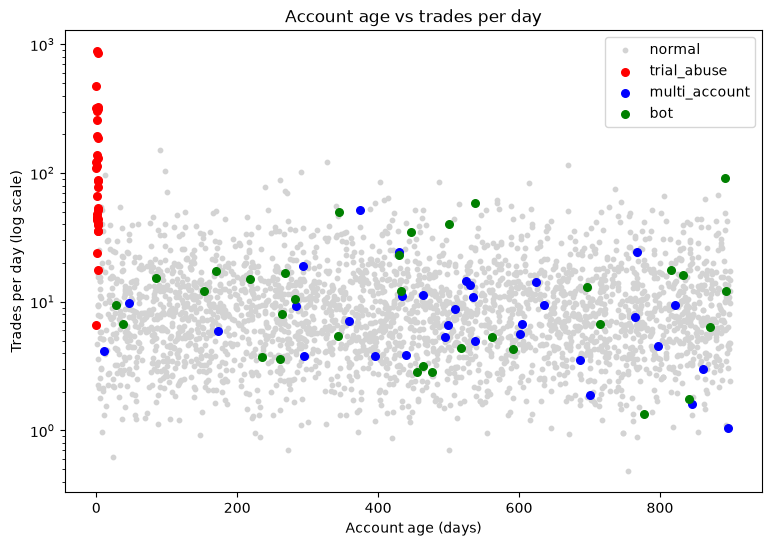

group
trial_abuse    33
normal         10
Name: count, dtype: int64


In [19]:
# Cell 6: account age vs trades per day, colored by account type

plt.figure(figsize=(9, 6))

# Draw normal accounts first (grey, in the background), then abusive types on top
normal = df[df["group"] == "normal"]
plt.scatter(normal["account_age_days"], normal["trades_per_day"],
            color="lightgrey", s=10, label="normal")

colors = {"trial_abuse": "red", "multi_account": "blue", "bot": "green"}
for name, color in colors.items():
    part = df[df["group"] == name]
    plt.scatter(part["account_age_days"], part["trades_per_day"],
                color=color, s=30, label=name)

plt.yscale("log")
plt.xlabel("Account age (days)")
plt.ylabel("Trades per day (log scale)")
plt.title("Account age vs trades per day")
plt.legend()

plt.savefig("../docs/figures/age_vs_trades.png", dpi=150, bbox_inches="tight")
plt.show()

# How many new accounts (age 0-3 days) are there in each group?
new_accounts = df[df["account_age_days"] <= 3]
print(new_accounts["group"].value_counts())

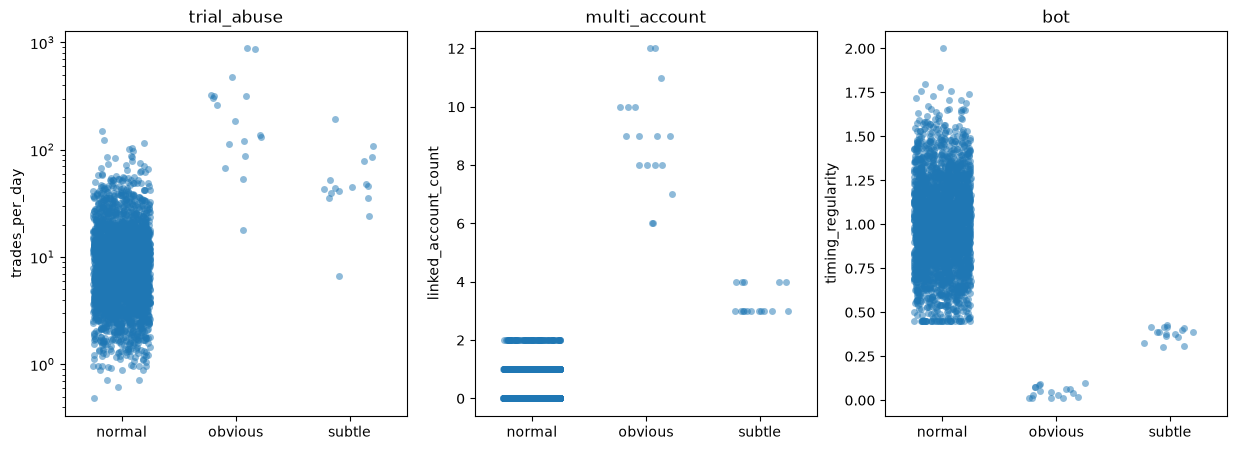

Subtle trial abuse inside normal range: 2 of 16
Subtle multi-account inside normal range: 0 of 16
Subtle bots inside normal range: 0 of 16


In [20]:
# Cell 7: obvious vs subtle anomalies (labels used only to color/group the charts)

# Give every account a level: normal, obvious or subtle
df["level"] = np.where(df["is_anomaly"] == 0, "normal", df["difficulty"])
order = ["normal", "obvious", "subtle"]

# Each abuse type and the one feature it changes
parts = [("trial_abuse", "trades_per_day"),
         ("multi_account", "linked_account_count"),
         ("bot", "timing_regularity")]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (abuse_type, col) in zip(axes, parts):
    # normal accounts + this one abuse type
    data = df[(df["group"] == "normal") | (df["group"] == abuse_type)]
    sns.stripplot(data=data, x="level", y=col, order=order, jitter=0.25, alpha=0.5, ax=ax)
    ax.set_title(abuse_type)
    ax.set_xlabel("")
axes[0].set_yscale("log")   # trades per day has the heavy tail

plt.savefig("../docs/figures/obvious_vs_subtle.png", dpi=150, bbox_inches="tight")
plt.show()

# How many subtle accounts hide inside the normal range?
normal = df[df["group"] == "normal"]
subtle = df[df["level"] == "subtle"]

trades_cut = normal["trades_per_day"].quantile(0.95)          # top 5% of normal
linked_cut = normal["linked_account_count"].quantile(0.95)    # top 5% of normal
timing_cut = normal["timing_regularity"].quantile(0.05)       # bottom 5% of normal

s_trial = subtle[subtle["group"] == "trial_abuse"]
s_multi = subtle[subtle["group"] == "multi_account"]
s_bot = subtle[subtle["group"] == "bot"]

print("Subtle trial abuse inside normal range:", (s_trial["trades_per_day"] <= trades_cut).sum(), "of", len(s_trial))
print("Subtle multi-account inside normal range:", (s_multi["linked_account_count"] <= linked_cut).sum(), "of", len(s_multi))
print("Subtle bots inside normal range:", (s_bot["timing_regularity"] >= timing_cut).sum(), "of", len(s_bot))

                         account_age_days  trades_per_day  \
account_age_days                     1.00           -0.10   
trades_per_day                      -0.10            1.00   
baseline_trades_per_day             -0.01            0.44   
linked_account_count                 0.03            0.01   
timing_regularity                   -0.02            0.01   

                         baseline_trades_per_day  linked_account_count  \
account_age_days                           -0.01                  0.03   
trades_per_day                              0.44                  0.01   
baseline_trades_per_day                     1.00                 -0.01   
linked_account_count                       -0.01                  1.00   
timing_regularity                          -0.01                  0.02   

                         timing_regularity  
account_age_days                     -0.02  
trades_per_day                        0.01  
baseline_trades_per_day              -0.01  
linked_a

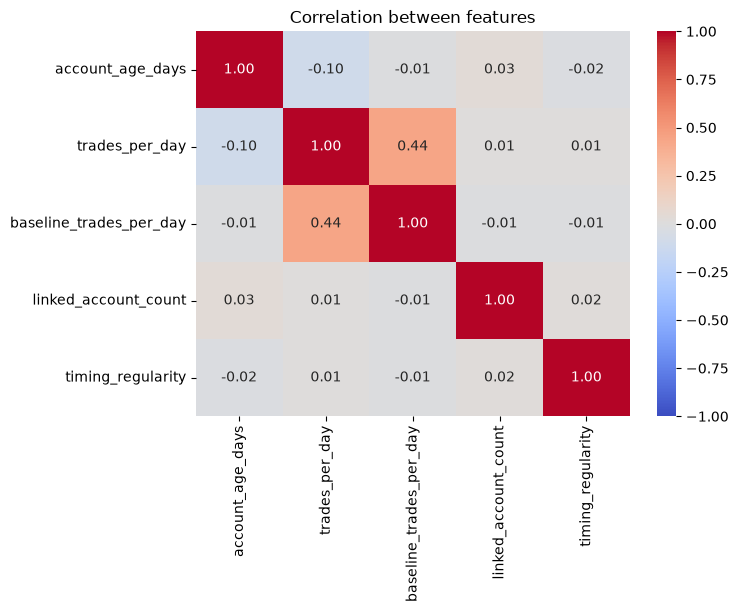

In [21]:
# Cell 8: correlation heatmap (features only, no labels)

feature_cols = ["account_age_days", "trades_per_day", "baseline_trades_per_day",
                "linked_account_count", "timing_regularity"]

corr = df[feature_cols].corr()
print(corr.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between features")

plt.savefig("../docs/figures/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Findings

1. **Trial abuse is the only type visible on trades per day, and it needs age and volume together.** Every trial abuser is brand new (age within the first few days). Obvious ones trade about 18 to 880 per day. Subtle ones mostly trade about 35 to 50 per day: 14 of 16 are above the 95th percentile of normal trades per day, and only 2 of 16 sit inside the normal range, including one at about 6.6 trades/day that only its age gives away. Since 10 normal accounts are also this new, age alone is not enough either.
2. **Multi-account separates on linked accounts alone.** Normal accounts have 0 to 2 linked accounts. Obvious cases have 6 to 12, and subtle cases have 3 to 4. Even the subtle ones sit just above the normal maximum of 2, so in this data they are close to normal but not inside it.
3. **Bots separate cleanly on timing regularity.** Normal accounts start at about 0.45. Obvious bots sit at about 0.01 to 0.1, and subtle bots at about 0.3 to 0.43, just below the normal range. There is a visible gap and no overlap.
4. **Trades per day is heavily skewed.** Median 8.03, mean 12.87, max 879.69. The extreme maximum comes from trial abusers. I will test a log transform in Phase 4 before scaling.
5. **The features are mostly independent.** The only notable correlation is trades per day with baseline trades per day (0.44). All other pairs are within ±0.10. The spike ratio (trades divided by baseline) will capture how unusual an account is relative to its own normal.
6. **No single feature catches all three abuse types.** On trades per day, abusive accounts mostly overlap with normal ones, apart from a tail of trial abusers, because only trial abuse changes that feature. Each abuse type shows up in a different feature, so the model needs all five. I expect subtle trial abuse to be the hardest case, especially for the z-score, which looks at one feature at a time.

In [22]:
# Cell 10: check that all figures were saved
import os
for f in sorted(os.listdir("../docs/figures")):
    print(f)

age_vs_trades.png
correlation_heatmap.png
linked_accounts.png
obvious_vs_subtle.png
timing_regularity.png
trades_per_day.png
